# LAB 09 - Fine-tune DistilBERT cho NER trên CoNLL-2003

- **Baseline:** token features → Logistic Regression (`baseline_ner.py`).
- **Transformer:** `distilbert-base-cased` + một Linear head trên **mọi token** (token classification).
- **Label alignment:** Strategy A. Token đầu của mỗi word mang nhãn, các subword sau nhận `-100` (xem `tokenizer_alignment.ipynb`).
- **Đánh giá:** entity-level P/R/F1 theo quy ước conlleval (`ner_data.py`): một entity chỉ đúng khi đúng cả loại lẫn ranh giới.

In [1]:
import os
os.environ["HF_HOME"] = os.path.abspath("../hf_models")          # đặt trước khi import transformers
os.environ["HF_HUB_OFFLINE"] = "1"

import platform
import random
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from transformers import AutoModelForTokenClassification, AutoTokenizer, get_linear_schedule_with_warmup

from baseline_ner import BaselineNER
from ner_data import LABEL2ID, LABELS, TYPES, entity_metrics, get_entities, load_conll, prf, token_metrics

QUICK = os.environ.get("LAB9_QUICK") == "1"
MODEL_NAME = "distilbert/distilbert-base-cased"
MAX_LEN, BATCH, LR, EPOCHS, WARMUP, SEED = 128, 32, 5e-5, 3, 0.1, 42
SAVE_DIR = os.path.join(os.environ["HF_HOME"], "lab9_ner_model" + ("_quick" if QUICK else ""))
torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
torch.set_num_threads(8)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 90)

train, val, test = load_conll("train"), load_conll("validation"), load_conll("test")
if QUICK:
    train, val, test, EPOCHS = train[:600], val[:200], test[:400], 1
gold_val, gold_test = [t for _, t in val], [t for _, t in test]

RESULTS = []
def log(experiment, model, setting, split, metric, value):
    RESULTS.append({"experiment": experiment, "model": model, "setting": setting, "split": split, "metric": metric, "value": value})

repro = {
    "Model": f"{MODEL_NAME} (6 layer, hidden 768, 12 head)",
    "Tokenizer": f"{MODEL_NAME} (WordPiece cased, 28,996 token)",
    "Dataset": "CoNLL-2003 (lhoestq/conll2003), 9 nhãn BIO",
    "Train / validation / test": f"{len(train)} / {len(val)} / {len(test)} câu",
    "Label alignment": "Strategy A: token đầu của word mang nhãn, subword sau = -100",
    "Max sequence length": MAX_LEN, "Batch size": BATCH, "Learning rate": LR, "Epochs": EPOCHS,
    "Optimizer": "AdamW (weight decay 0.01), linear warmup 10% + decay, clip 1.0, batch gom theo độ dài",
    "Random seed": SEED,
    "Hardware": f"CPU {platform.processor()}, {torch.get_num_threads()} threads, không GPU",
    "torch": torch.__version__,
}
pd.Series(repro)

Model                                              distilbert/distilbert-base-cased (6 layer, hidden 768, 12 head)
Tokenizer                                         distilbert/distilbert-base-cased (WordPiece cased, 28,996 token)
Dataset                                                                 CoNLL-2003 (lhoestq/conll2003), 9 nhãn BIO
Train / validation / test                                                                  14041 / 3250 / 3453 câu
Label alignment                                       Strategy A: token đầu của word mang nhãn, subword sau = -100
Max sequence length                                                                                            128
Batch size                                                                                                      32
Learning rate                                                                                              0.00005
Epochs                                                                          

## 1. Baseline: token features + Logistic Regression

In [2]:
t0 = time.perf_counter()
baseline = BaselineNER().fit(train)
base_train_time = time.perf_counter() - t0
t0 = time.perf_counter()
base_pred = baseline.predict(test)
base_infer_time = time.perf_counter() - t0
print(f"baseline: train {base_train_time:.0f} s, {len(baseline.vec.vocabulary_):,} features")
print("test entity F1:", round(entity_metrics(gold_test, base_pred)["ALL"]["f1"], 4))

E:\hus\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


baseline: train 121 s, 214,465 features
test entity F1: 0.7736


## 2. Transformer token classification

### 2.1. Tokenize + alignment

In [3]:
tok = AutoTokenizer.from_pretrained(MODEL_NAME)

def encode(sents):
    enc = tok([w for w, _ in sents], is_split_into_words=True, truncation=True, max_length=MAX_LEN)
    items = []
    for b, (words, tags) in enumerate(sents):
        wid, labels, prev = enc.word_ids(b), [], None
        for w in wid:
            labels.append(-100 if w is None or w == prev else LABEL2ID[tags[w]])     # Strategy A
            prev = w
        items.append({"input_ids": enc["input_ids"][b], "labels": labels, "word_ids": wid, "n_words": len(words)})
    return items

def collate(items):
    L = max(len(it["input_ids"]) for it in items)
    ids = torch.full((len(items), L), tok.pad_token_id)
    lab = torch.full((len(items), L), -100)
    am = torch.zeros((len(items), L), dtype=torch.long)
    for i, it in enumerate(items):
        n = len(it["input_ids"])
        ids[i, :n], lab[i, :n], am[i, :n] = torch.tensor(it["input_ids"]), torch.tensor(it["labels"]), 1
    return {"input_ids": ids, "attention_mask": am, "labels": lab}

tr_items, va_items, te_items = encode(train), encode(val), encode(test)
n_cut = sum(max(w for w in it["word_ids"] if w is not None) + 1 < it["n_words"] for it in tr_items + va_items + te_items)
print(f"số câu bị cắt ở {MAX_LEN} token: {n_cut}")

số câu bị cắt ở 128 token: 7


### 2.2. Nhìn vào một batch: tokens, input_ids, attention_mask, word_ids, labels, logits, predictions

In [4]:
model = AutoModelForTokenClassification.from_pretrained(
    MODEL_NAME, num_labels=len(LABELS), id2label=dict(enumerate(LABELS)), label2id=LABEL2ID)
n_params = sum(p.numel() for p in model.parameters())
print(f"params: {n_params:,} | head: {model.classifier.weight.shape} + bias {model.classifier.bias.shape}")

demo_idx = [i for i, (w, _) in enumerate(test) if 6 <= len(w) <= 10 and sum(t != "O" for t in test[i][1]) >= 2][:2]
demo = collate([te_items[i] for i in demo_idx])

def show_batch(model, title):
    model.eval()
    with torch.no_grad():
        logits = model(input_ids=demo["input_ids"], attention_mask=demo["attention_mask"]).logits
    print(title, "| input_ids", tuple(demo["input_ids"].shape), "| logits", tuple(logits.shape), "| labels", tuple(demo["labels"].shape))
    pred = logits.argmax(-1)
    for r, i in enumerate(demo_idx):
        n = len(te_items[i]["input_ids"])
        print(pd.DataFrame({
            "token": tok.convert_ids_to_tokens(demo["input_ids"][r, :n]), "input_id": demo["input_ids"][r, :n].tolist(),
            "attention_mask": demo["attention_mask"][r, :n].tolist(),
            "word_id": ["-" if w is None else w for w in te_items[i]["word_ids"]],
            "label": ["IGN" if l == -100 else LABELS[l] for l in demo["labels"][r, :n].tolist()],
            "prediction": [LABELS[p] for p in pred[r, :n].tolist()]}).T.to_string(header=False), "\n")

show_batch(model, "TRƯỚC khi train (head ngẫu nhiên)")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForTokenClassification LOAD REPORT from: distilbert/distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


params: 65,197,833 | head: torch.Size([9, 768]) + bias torch.Size([9])


TRƯỚC khi train (head ngẫu nhiên) | input_ids (2, 27) | logits (2, 27, 9) | labels (2, 27)
token           [CLS]     AL      -     AI    ##N      ,  United   Arab  Emirates   1996      -     12      -     06  [SEP]
input_id          101  18589    118  19016   2249    117    1244   4699     14832   1820    118   1367    118   5037    102
attention_mask      1      1      1      1      1      1       1      1         1      1      1      1      1      1      1
word_id             -      0      0      0      0      1       2      3         4      5      5      5      5      5      -
label             IGN  B-LOC    IGN    IGN    IGN      O   B-LOC  I-LOC     I-LOC      O    IGN    IGN    IGN    IGN    IGN
prediction      I-ORG  I-PER  I-ORG  I-PER  I-PER  I-ORG   I-PER  I-PER     I-PER  I-ORG  I-ORG  I-ORG  I-ORG  I-ORG      O 

token           [CLS]      S   ##OC   ##CE    ##R      -     LA   ##TE     GO   ##AL    ##S      G  ##IVE      J   ##AP   ##AN      W   ##IN      O   ##VE    ##R  

### 2.3. Fine-tuning

Batch được gom theo độ dài: xáo trộn, rồi sắp xếp trong từng nhóm 50 batch, để giảm padding và chạy nhanh hơn trên CPU. Sau mỗi epoch tính entity F1 trên validation, giữ checkpoint tốt nhất.

In [5]:
def batches(items, shuffle, rng=None):
    idx = rng.permutation(len(items)) if shuffle else np.argsort([len(it["input_ids"]) for it in items])
    if shuffle:
        mega = BATCH * 50
        idx = np.concatenate([sorted(idx[i:i + mega], key=lambda j: len(items[j]["input_ids"])) for i in range(0, len(idx), mega)])
    bs = [idx[i:i + BATCH] for i in range(0, len(idx), BATCH)]
    if shuffle:
        rng.shuffle(bs)
    return bs

@torch.no_grad()
def predict(model, items):
    """Nhãn mức word lấy ở token đầu của mỗi word. Word bị cắt (ngoài MAX_LEN) nhận O."""
    model.eval()
    tags, conf = [None] * len(items), [None] * len(items)
    for bi in batches(items, False):
        x = collate([items[j] for j in bi])
        P = model(input_ids=x["input_ids"], attention_mask=x["attention_mask"]).logits.softmax(-1)
        for r, j in enumerate(bi):
            t, c, prev = ["O"] * items[j]["n_words"], [1.0] * items[j]["n_words"], None
            for pos, w in enumerate(items[j]["word_ids"]):
                if w is not None and w != prev:
                    k = int(P[r, pos].argmax())
                    t[w], c[w] = LABELS[k], float(P[r, pos, k])
                prev = w
            tags[j], conf[j] = t, c
    return tags, conf

opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
steps = EPOCHS * ((len(tr_items) + BATCH - 1) // BATCH)
sched = get_linear_schedule_with_warmup(opt, int(WARMUP * steps), steps)
rng = np.random.default_rng(SEED)
hist, best, t_start = [], None, time.perf_counter()
for ep in range(1, EPOCHS + 1):
    model.train()
    t0, tot, n = time.perf_counter(), 0.0, 0
    for s, bi in enumerate(batches(tr_items, True, rng)):
        loss = model(**collate([tr_items[j] for j in bi])).loss
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step()
        tot, n = tot + loss.item() * len(bi), n + len(bi)
        if s % 100 == 0:
            print(f"  epoch {ep} step {s}: loss {loss.item():.4f} ({time.perf_counter() - t0:.0f} s)", flush=True)
    train_time = time.perf_counter() - t0
    vp, _ = predict(model, va_items)
    ev = entity_metrics(gold_val, vp)["ALL"]
    hist.append({"epoch": ep, "train_loss": tot / n, "val_entity_P": ev["precision"], "val_entity_R": ev["recall"],
                 "val_entity_F1": ev["f1"], "epoch_time_s": train_time})
    print(f"epoch {ep}: train_loss {tot / n:.4f} | val entity F1 {ev['f1']:.4f} ({train_time:.0f} s)", flush=True)
    if best is None or ev["f1"] > best[0]:
        best = (ev["f1"], ep, {k: v.detach().clone() for k, v in model.state_dict().items()})
tf_train_time = time.perf_counter() - t_start
model.load_state_dict(best[2])
print(f"best epoch {best[1]} (val F1 {best[0]:.4f}), tổng thời gian train {tf_train_time / 60:.1f} phút")
for h in hist:
    for k, v in h.items():
        if k != "epoch":
            log("training", "Transformer", f"epoch={h['epoch']}", "validation", k, v)
pd.DataFrame(hist).set_index("epoch").round(4)

  epoch 1 step 0: loss 2.2573 (1 s)


  epoch 1 step 100: loss 0.2177 (157 s)


  epoch 1 step 200: loss 0.1747 (329 s)


  epoch 1 step 300: loss 0.0608 (522 s)


  epoch 1 step 400: loss 0.0743 (705 s)


epoch 1: train_loss 0.2741 | val entity F1 0.9072 (780 s)


... (10 outputs left out)

  epoch 3 step 400: loss 0.0035 (745 s)


epoch 3: train_loss 0.0141 | val entity F1 0.9360 (820 s)


best epoch 3 (val F1 0.9360), tổng thời gian train 40.0 phút


,train_loss,val_entity_P,val_entity_R,val_entity_F1,epoch_time_s
epoch,,,,,
1,0.2741,0.9050,0.9095,0.9072,780.2563
2,0.0334,0.9254,0.9310,0.9282,664.4269
3,0.0141,0.9312,0.9408,0.9360,820.3415


In [6]:
show_batch(model, "SAU khi train")
model.save_pretrained(SAVE_DIR); tok.save_pretrained(SAVE_DIR)
print("đã lưu model vào", SAVE_DIR)

SAU khi train | input_ids (2, 27) | logits (2, 27, 9) | labels (2, 27)
token           [CLS]     AL    -     AI    ##N    ,  United   Arab  Emirates  1996    -    12    -    06  [SEP]
input_id          101  18589  118  19016   2249  117    1244   4699     14832  1820  118  1367  118  5037    102
attention_mask      1      1    1      1      1    1       1      1         1     1    1     1    1     1      1
word_id             -      0    0      0      0    1       2      3         4     5    5     5    5     5      -
label             IGN  B-LOC  IGN    IGN    IGN    O   B-LOC  I-LOC     I-LOC     O  IGN   IGN  IGN   IGN    IGN
prediction          O  B-LOC    O  B-LOC  I-ORG    O   B-LOC  I-LOC     I-LOC     O    O     O    O     O      O 

token           [CLS]    S  ##OC   ##CE   ##R    -     LA   ##TE     GO   ##AL   ##S    G  ##IVE      J   ##AP   ##AN    W   ##IN    O   ##VE   ##R      S   ##Y   ##RI   ##A    .  [SEP]
input_id          101  156  9244  10954  2069  118  10722  1288

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

đã lưu model vào E:\hus\nlp\hf_models\lab9_ner_model


In [7]:
t0 = time.perf_counter()
tf_pred, tf_conf = predict(model, te_items)
tf_infer_time = time.perf_counter() - t0
base_conf = baseline.predict_proba(test)
PRED = {"Baseline": base_pred, "Transformer": tf_pred}

## 3. Experiment 2 - Baseline vs Transformer (cùng test set, entity-level)

In [8]:
rows = []
for name, pred in PRED.items():
    e, t = entity_metrics(gold_test, pred)["ALL"], token_metrics(gold_test, pred)
    rows.append({"model": name, "precision": e["precision"], "recall": e["recall"], "f1": e["f1"],
                 "train_time_s": base_train_time if name == "Baseline" else tf_train_time,
                 "infer_time_s": base_infer_time if name == "Baseline" else tf_infer_time,
                 "params": len(baseline.vec.vocabulary_) * len(LABELS) if name == "Baseline" else n_params})
    for k in ["precision", "recall", "f1", "tp", "fp", "fn"]:
        log("exp2_baseline_vs_transformer", name, "entity-level", "test", k, e[k])
    for k in ["train_time_s", "infer_time_s", "params"]:
        log("exp2_baseline_vs_transformer", name, "-", "test", k, rows[-1][k])
exp2 = pd.DataFrame(rows).set_index("model")
exp2.round(4)

,precision,recall,f1,train_time_s,infer_time_s,params
model,,,,,,
Baseline,0.7531,0.7951,0.7736,121.0418,1.9498,1930185
Transformer,0.8853,0.9032,0.8941,2401.2605,49.8213,65197833


**Nhận xét Experiment 2** (cùng test set 3,453 câu, entity-level)

| Model | Precision | Recall | F1 | Train time | Params |
|---|---|---|---|---|---|
| Baseline (token features + LR) | 0.753 | 0.795 | 0.774 | 2 phút | 1.9M |
| DistilBERT fine-tune | 0.885 | 0.903 | **0.894** | 40 phút | 65.2M |

- Transformer hơn baseline 12.1 điểm F1, và tăng ở cả precision (+13.2) lẫn recall (+10.8).
- Cái giá là thời gian train dài hơn 20 lần và inference chậm hơn 25 lần (50 s so với 2 s) trên CPU.
- Baseline không yếu: chỉ với dạng chữ, prefix/suffix và cửa sổ ±2 từ đã đạt 0.774. Phần Transformer thêm vào nằm ở những chỗ cần ngữ cảnh và ở entity chưa gặp (xem Exp 4, Exp 5).

## 4. Experiment 3 - Token-level vs entity-level

In [9]:
def overlap(a, b):
    return a[1] < b[2] and b[1] < a[2]

def error_breakdown(gold_seqs, pred_seqs):
    """Phân loại lỗi mức entity: spurious (FP không chạm gold), missing (FN không chạm pred),
    wrong type (đúng span, sai loại), boundary (chồng lấn nhưng khác span)."""
    c = Counter()
    for g, p in zip(gold_seqs, pred_seqs):
        G, P = get_entities(g), get_entities(p)
        c["correct"] += len(G & P)
        for e in P - G:
            hits = [x for x in G if overlap(e, x)]
            if not hits:
                c["spurious (FP)"] += 1
            elif any(x[1:] == e[1:] for x in hits):
                c["wrong type"] += 1
            else:
                c["boundary"] += 1
        for e in G - P:
            if not any(overlap(e, x) for x in P):
                c["missing (FN)"] += 1
    return c

rows = []
for name, pred in PRED.items():
    t, e = token_metrics(gold_test, pred), entity_metrics(gold_test, pred)["ALL"]
    rows.append({"model": name, "token accuracy": t["accuracy"], "token P": t["precision"], "token R": t["recall"],
                 "token F1": t["f1"], "entity P": e["precision"], "entity R": e["recall"], "entity F1": e["f1"],
                 **error_breakdown(gold_test, pred)})
    for k in ["accuracy", "precision", "recall", "f1"]:
        log("exp3_token_vs_entity", name, "token-level", "test", k, t[k])
exp3 = pd.DataFrame(rows).set_index("model")
exp3.round(4)

,token accuracy,token P,token R,token F1,entity P,entity R,entity F1,correct,wrong type,boundary,spurious (FP),missing (FN)
model,,,,,,,,,,,,
Baseline,0.9615,0.8263,0.8222,0.8243,0.7531,0.7951,0.7736,4491,520,711,241,222
Transformer,0.9789,0.9029,0.9181,0.9105,0.8853,0.9032,0.8941,5101,253,209,199,105


In [10]:
print("Ví dụ: gần hết token đúng nhưng entity sai (Transformer)")
shown = 0
for (words, g), p in zip(test, tf_pred):
    G, P = get_entities(g), get_entities(p)
    tok_acc = np.mean([a == b for a, b in zip(g, p)])
    bad = [e for e in G - P if any(overlap(e, x) for x in P)]
    if bad and tok_acc >= 0.85 and len(words) <= 20 and shown < 3:
        e = bad[0]
        print(" ".join(words))
        print(f"  entity '{' '.join(words[e[1]:e[2]])}': gold {g[e[1]:e[2]]} pred {p[e[1]:e[2]]} | token accuracy câu = {tok_acc:.2f}\n")
        shown += 1

Ví dụ: gần hết token đúng nhưng entity sai (Transformer)
SOCCER - ASIAN CUP GROUP C RESULTS .
  entity 'ASIAN CUP': gold ['B-MISC', 'I-MISC'] pred ['B-MISC', 'I-MISC'] | token accuracy câu = 0.88

SOCCER - ENGLISH F.A. CUP SECOND ROUND RESULT .
  entity 'ENGLISH F.A. CUP': gold ['B-MISC', 'I-MISC', 'I-MISC'] pred ['B-MISC', 'B-MISC', 'I-MISC'] | token accuracy câu = 0.89

Pau-Orthez ( France ) 9 5 4 14
  entity 'Pau-Orthez': gold ['B-ORG'] pred ['B-PER'] | token accuracy câu = 0.88



**Nhận xét Experiment 3**

| Model | Token accuracy | Token F1 (không tính O) | Entity F1 |
|---|---|---|---|
| Baseline | 0.962 | 0.824 | 0.774 |
| Transformer | 0.979 | 0.911 | 0.894 |

- **Token accuracy đánh lừa:** baseline đạt 96.2% vì khoảng 83% word có nhãn O. Tính theo entity thì chỉ còn 0.774.
- Entity F1 luôn thấp hơn token F1 (thấp hơn 5.0 điểm ở baseline, 1.6 điểm ở Transformer), vì một token sai làm hỏng cả entity. Ví dụ "ENGLISH F.A. CUP": Transformer đoán `B-MISC B-MISC I-MISC`, đúng 2 trên 3 token, nhưng entity bị tách đôi nên tính là sai.
- Khoảng cách giữa hai mức ở baseline lớn hơn, vì baseline phân loại từng word độc lập nên hay sai ranh giới: 711 lỗi boundary, so với 209 của Transformer.
- Lỗi của Transformer trên 5,648 gold entity: 253 sai loại, 209 sai ranh giới, 199 thừa (FP), 105 thiếu (FN). Model hiếm khi bỏ sót entity, lỗi chủ yếu là sai loại và sai ranh giới.

## 5. Experiment 4 - Theo loại entity

In [11]:
train_ents = Counter()
train_surface = Counter()
for words, tags in train:
    for typ, s, e in get_entities(tags):
        train_ents[typ] += 1
        train_surface[(" ".join(words[s:e]), typ)] += 1
seen_surface = Counter()
for (text, typ), n in train_surface.items():
    seen_surface[text] += n

rows = []
for name, pred in PRED.items():
    em = entity_metrics(gold_test, pred)
    for typ in TYPES:
        test_ents = [(" ".join(w[s:e]), t) for (w, g) in test for (t, s, e) in get_entities(g) if t == typ]
        rows.append({"model": name, "type": typ, "precision": em[typ]["precision"], "recall": em[typ]["recall"],
                     "f1": em[typ]["f1"], "test support": len(test_ents), "train entities": train_ents[typ],
                     "% test chưa gặp trong train": 100 * np.mean([seen_surface[x] == 0 for x, _ in test_ents])})
        for k in ["precision", "recall", "f1"]:
            log("exp4_entity_type", name, typ, "test", k, em[typ][k])
entity_df = pd.DataFrame(rows)
entity_df.round(4).to_csv("entity_metrics.csv", index=False)
tbl = entity_df.pivot(index="type", columns="model", values=["precision", "recall", "f1"]).round(3)
tbl.columns = [f"{m} {k}" for k, m in tbl.columns]
tbl.join(
    entity_df[entity_df.model == "Transformer"].set_index("type")[["test support", "train entities", "% test chưa gặp trong train"]].round(1))

,Baseline precision,Transformer precision,Baseline recall,Transformer recall,Baseline f1,Transformer f1,test support,train entities,% test chưa gặp trong train
type,,,,,,,,,
LOC,0.831,0.930,0.864,0.914,0.847,0.922,1668,7140,17.9
MISC,0.756,0.729,0.765,0.801,0.761,0.763,702,3438,32.3
ORG,0.658,0.850,0.695,0.892,0.676,0.870,1661,6321,41.9
PER,0.770,0.953,0.840,0.949,0.803,0.951,1617,6600,85.3


In [12]:
print("Nhầm loại khi đúng span (Transformer): gold → pred")
conf_type = Counter()
for g, p in zip(gold_test, tf_pred):
    P = {e[1:]: e[0] for e in get_entities(p)}
    for typ, s, e in get_entities(g):
        if (s, e) in P and P[(s, e)] != typ:
            conf_type[f"{typ} → {P[(s, e)]}"] += 1
pd.Series(conf_type).sort_values(ascending=False).head(8)

Nhầm loại khi đúng span (Transformer): gold → pred


LOC → ORG     52
ORG → LOC     33
MISC → ORG    30
ORG → MISC    30
PER → ORG     27
ORG → PER     23
LOC → MISC    18
MISC → LOC    12
dtype: int64

**Nhận xét Experiment 4** (đã lưu vào `entity_metrics.csv`)

| Entity | Baseline F1 | Transformer P / R / F1 | Entity trong train | % test chưa gặp trong train |
|---|---|---|---|---|
| PER | 0.803 | 0.953 / 0.949 / **0.951** | 6,600 | 85.3 |
| LOC | 0.847 | 0.930 / 0.914 / 0.922 | 7,140 | 17.9 |
| ORG | 0.676 | 0.850 / 0.892 / 0.870 | 6,321 | 41.9 |
| MISC | 0.761 | 0.729 / 0.801 / 0.763 | 3,438 | 32.3 |

- **PER cao nhất dù 85% tên người trong test chưa từng gặp.** Tên người có pattern và ngữ cảnh rõ (họ + tên, đứng trước "said", sau chức danh), nên model không cần nhớ tên. Đây cũng là loại Transformer cải thiện nhiều (+14.8 điểm).
- **LOC** dễ vì là tập gần như đóng: chỉ 18% chưa gặp, nên ngay cả baseline cũng đạt 0.847.
- **ORG** cải thiện nhiều nhất (+19.4 điểm) nhưng vẫn thấp hơn PER và LOC. ORG mơ hồ với LOC: tên đội thể thao trùng tên thành phố, và LOC ↔ ORG là cặp nhầm nhiều nhất (85 lần). Ranh giới của ORG cũng khó vì tên dài, có chứa từ thường.
- **MISC thấp nhất và gần như không cải thiện** (0.761 → 0.763). Đây là lớp "còn lại" không đồng nhất (quốc tịch, sự kiện, sản phẩm), có ít dữ liệu train nhất, và ranh giới với ORG không rõ (60 lần nhầm MISC ↔ ORG).

## 6. Experiment 5 - Độ dài entity, số subword, entity hiếm

- **Theo độ dài (số word):** recall tính theo độ dài của gold entity, precision theo độ dài của predicted entity.
- **Theo số subword** của entity: chỉ tính recall.
- **Theo số lần entity (cùng chuỗi chữ) xuất hiện trong train:** chỉ tính recall. Dùng để kiểm tra prediction 3.

In [13]:
def length_bin(n):
    return "4+" if n >= 4 else str(n)

def freq_bin(n):
    return "0 (chưa gặp)" if n == 0 else "1-2" if n <= 2 else "3-9" if n <= 9 else "10+"

def sub_bin(n):
    return "1" if n == 1 else "2-3" if n <= 3 else "4-5" if n <= 5 else "6+"

ent_rows = []        # một dòng cho mỗi gold entity và mỗi predicted entity
for name, pred in PRED.items():
    for (words, g), p in zip(test, pred):
        G, P = get_entities(g), get_entities(p)
        for kind, S, other in [("gold", G, P), ("pred", P, G)]:
            for typ, s, e in S:
                text = " ".join(words[s:e])
                ent_rows.append({"model": name, "kind": kind, "type": typ, "correct": (typ, s, e) in other,
                                 "length": length_bin(e - s), "subwords": sub_bin(len(tok.tokenize(text))),
                                 "freq": freq_bin(seen_surface[text]), "caps": all(w.isupper() for w in words if w.isalpha()),
                                 "text": text})
E = pd.DataFrame(ent_rows)

def by(col, kinds=("gold", "pred")):
    out = {}
    for name in PRED:
        r = E[(E.model == name) & (E.kind == "gold")].groupby(col).correct.agg(["mean", "size"])
        if "pred" in kinds:
            p = E[(E.model == name) & (E.kind == "pred")].groupby(col).correct.mean()
            out[(name, "P")] = p
        out[(name, "R")] = r["mean"]
        if "pred" in kinds:
            out[(name, "F1")] = 2 * p * r["mean"] / (p + r["mean"])
        out[("n gold", "")] = r["size"]
    return pd.DataFrame(out)

exp5_len = by("length")
exp5_sub = by("subwords", kinds=("gold",))
exp5_freq = by("freq", kinds=("gold",)).reindex(["0 (chưa gặp)", "1-2", "3-9", "10+"])
for name in PRED:
    for b, v in exp5_len[(name, "F1")].items():
        log("exp5_entity_length", name, f"length={b}", "test", "f1", v)
    for b, v in exp5_freq[(name, "R")].items():
        log("exp5_rare_entity", name, f"train_freq={b}", "test", "recall", v)
    for b, v in exp5_sub[(name, "R")].items():
        log("exp5_subwords", name, f"subwords={b}", "test", "recall", v)
print("Theo độ dài entity (word)"); display(exp5_len.round(3))
print("Theo số subword của entity"); display(exp5_sub.round(3))
print("Theo tần suất trong train"); display(exp5_freq.round(3))
print("Câu viết hoa toàn bộ (headline) vs câu thường, recall")
display(E[E.kind == "gold"].groupby(["caps", "model"]).correct.agg(["mean", "size"]).unstack().round(3))

Theo độ dài entity (word)


Baseline               n gold Transformer              
              P      R     F1                  P      R     F1
length                                                        
1         0.707  0.811  0.756   3574       0.878  0.903  0.890
2         0.865  0.809  0.836   1776       0.906  0.910  0.908
3         0.772  0.559  0.649    236       0.855  0.852  0.854
4+        0.688  0.355  0.468     62       0.824  0.903  0.862

Theo số subword của entity


,Baseline,n gold,Transformer
,R,,R
subwords,,,
1,0.864,1923,0.925
2-3,0.732,1979,0.884
4-5,0.799,1275,0.908
6+,0.769,471,0.881


Theo tần suất trong train


,Baseline,n gold,Transformer
,R,,R
freq,,,
0 (chưa gặp),0.664,2600,0.863
1-2,0.779,616,0.885
3-9,0.893,796,0.923
10+,0.962,1636,0.965


Câu viết hoa toàn bộ (headline) vs câu thường, recall


mean                 size            
model Baseline Transformer Baseline Transformer
caps                                           
False    0.794       0.915     5040        5040
True     0.808       0.806      608         608

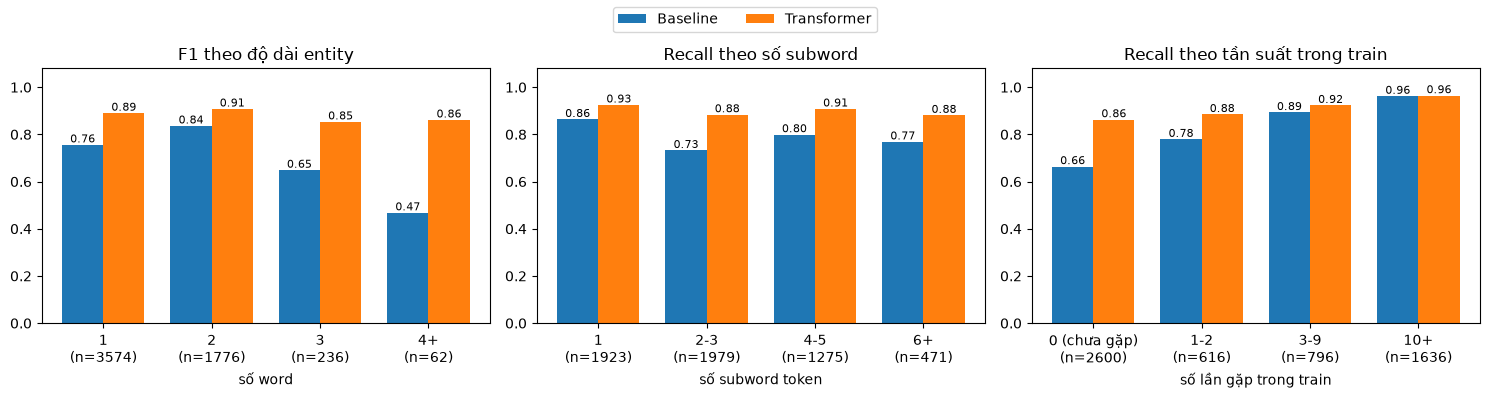

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (df, metric, title, xl) in zip(axes, [(exp5_len, "F1", "F1 theo độ dài entity", "số word"),
                                               (exp5_sub, "R", "Recall theo số subword", "số subword token"),
                                               (exp5_freq, "R", "Recall theo tần suất trong train", "số lần gặp trong train")]):
    x = np.arange(len(df))
    for k, name in enumerate(PRED):
        v = df[(name, metric)].values
        ax.bar(x + (k - 0.5) * 0.38, v, 0.38, label=name)
        for xi, vi in zip(x, v):
            ax.text(xi + (k - 0.5) * 0.38, vi + 0.01, f"{vi:.2f}", ha="center", fontsize=8)
    ax.set_xticks(x, [f"{i}\n(n={n})" for i, n in zip(df.index, df[("n gold", "")])])
    ax.set(title=title, xlabel=xl, ylim=(0, 1.08))
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=2)
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.savefig("entity_length_analysis.png", dpi=120)
plt.show()

**Nhận xét Experiment 5**

| | 1 word | 2 word | 3 word | 4+ word |
|---|---|---|---|---|
| Baseline F1 | 0.756 | 0.836 | 0.649 | 0.468 |
| Transformer F1 | 0.890 | 0.908 | 0.854 | 0.862 |

- **Độ dài.** Baseline sụp đổ ở entity dài (0.468 ở 4+ word), vì mỗi word được đoán độc lập và chỉ thấy ±2 từ. Transformer gần như không bị ảnh hưởng (0.85 - 0.91). Entity 2 word cao nhất ở cả hai model vì đa số là tên người. Nhóm 4+ chỉ có 62 entity nên số liệu dao động.
- **Số subword.** Recall của Transformer là 0.925 với entity 1 subword và 0.88 - 0.91 với entity bị tách. Bị tách thành nhiều mảnh chỉ làm giảm nhẹ, nên Strategy A (chỉ gán nhãn cho token đầu) không gây hại lớn.
- **Entity hiếm.** Recall của Transformer tăng từ 0.863 (chưa gặp) lên 0.965 (gặp từ 10 lần). Baseline tăng từ 0.664 lên 0.962. Với entity quen thuộc, hai model ngang nhau. Gần như toàn bộ lợi thế của Transformer nằm ở entity chưa gặp (+19.9 điểm).
- **Headline viết hoa toàn bộ.** Recall của Transformer giảm từ 0.915 xuống 0.806, bằng baseline (0.808). Đây là hệ quả của tokenization: "GERMANY" thành 5 mảnh vô nghĩa và model mất tín hiệu viết hoa.

## 7. Confusion matrix (mức word, 9 nhãn BIO)

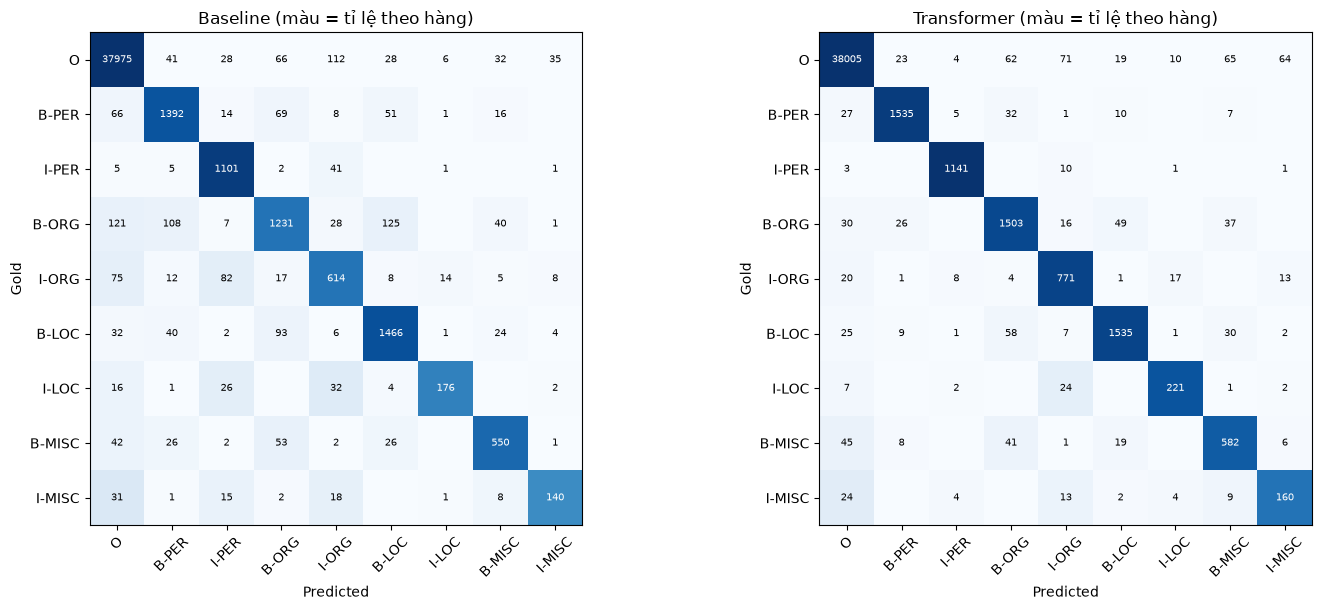

In [15]:
from sklearn.metrics import confusion_matrix
fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
for ax, (name, pred) in zip(axes, PRED.items()):
    g = [t for s in gold_test for t in s]
    p = [t for s in pred for t in s]
    cm = confusion_matrix(g, p, labels=LABELS)
    cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            if cm[i, j]:
                ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=7, color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_xticks(range(len(LABELS)), LABELS, rotation=45); ax.set_yticks(range(len(LABELS)), LABELS)
    ax.set(title=f"{name} (màu = tỉ lệ theo hàng)", xlabel="Predicted", ylabel="Gold")
    for i, l in enumerate(LABELS):
        log("confusion_matrix", name, l, "test", "row_recall", cmn[i, i])
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=120)
plt.show()

## 8. Experiment 6 - Error analysis

In ngẫu nhiên (seed cố định) các lỗi của Transformer theo 4 nhóm. Mỗi lỗi kèm câu, gold, prediction, confidence ở word đầu entity, số lần gặp trong train, và dự đoán của baseline cho cùng span.

In [16]:
err = {"spurious (FP)": [], "missing (FN)": [], "boundary": [], "wrong type": []}
for i, ((words, g), p) in enumerate(zip(test, tf_pred)):
    G, P = get_entities(g), get_entities(p)
    for e in P - G:
        hits = [x for x in G if overlap(e, x)]
        key = "spurious (FP)" if not hits else "wrong type" if any(x[1:] == e[1:] for x in hits) else "boundary"
        err[key].append((i, e, hits))
    for e in G - P:
        if not any(overlap(e, x) for x in P):
            err["missing (FN)"].append((i, e, []))

def ent_str(words, ents):
    return "; ".join(f"[{' '.join(words[s:e])}]/{t}" for t, s, e in sorted(ents, key=lambda x: x[1])) or "-"

rng_err = np.random.default_rng(0)
for key, items in err.items():
    print(f"\n===== {key}: {len(items)} lỗi =====")
    for k in rng_err.choice(len(items), min(8, len(items)), replace=False):
        i, e, hits = items[k]
        words, g = test[i]
        span = range(min([e[1]] + [h[1] for h in hits]), max([e[2]] + [h[2] for h in hits]))
        lo, hi = max(0, span.start - 6), min(len(words), span.stop + 6)
        print(f"#{i}: ...{' '.join(words[lo:hi])}...")
        gold_here = [x for x in get_entities(g) if overlap(x, (None, span.start, span.stop))]
        pred_here = [x for x in get_entities(tf_pred[i]) if overlap(x, (None, span.start, span.stop))]
        base_here = [x for x in get_entities(base_pred[i]) if overlap(x, (None, span.start, span.stop))]
        print(f"   gold: {ent_str(words, gold_here)} | pred: {ent_str(words, pred_here)} (conf {tf_conf[i][e[1]]:.2f}) "
              f"| baseline: {ent_str(words, base_here)} | train freq '{' '.join(words[e[1]:e[2]])}': {seen_surface[' '.join(words[e[1]:e[2]])]}")


===== spurious (FP): 199 lỗi =====
#2293: ...up of the State Council 's Port Office , the Civil Aviation Administration of...
   gold: - | pred: [Port Office]/ORG (conf 0.94) | baseline: [Port Office]/ORG | train freq 'Port Office': 0
#416: ...on Thursday but last year 's AFC finalists rallied together to shoot down...
   gold: - | pred: [AFC]/ORG (conf 0.74) | baseline: - | train freq 'AFC': 0
#34: ...SOCCER - LATE GOALS GIVE JAPAN WIN OVER SYRIA...
   gold: - | pred: [LATE]/PER (conf 0.39) | baseline: - | train freq 'LATE': 0
#1691: ...Holsteins - ( grade and weight )...
   gold: - | pred: [Holsteins]/MISC (conf 0.86) | baseline: - | train freq 'Holsteins': 0
#1293: ...Polish ex-communist president to visit Pope ....
   gold: - | pred: [Pope]/PER (conf 0.97) | baseline: [Pope]/LOC | train freq 'Pope': 0
#1124: ...WESTERN HEMISPHERE -...
   gold: - | pred: [WESTERN]/MISC (conf 0.34) | baseline: [WESTERN]/MISC | train freq 'WESTERN': 0
#298: ...CRICKET - LARA SUFFERS MORE AUSTRALIAN T

**Nhận xét Experiment 6** (bảng chi tiết trong `error_analysis.md`)

- **Spurious (199):** phần lớn là từ viết hoa không phải entity theo gold ("Pope", "East", "Port Office"), và từ in hoa trong headline ("LATE", "WESTERN") với confidence thấp (0.3 - 0.4).
- **Missing (105):** chủ yếu là từ in hoa trong headline ("CHICAGO", "REAL MADRID") và từ thường được dùng làm tên ("Association", "Network", "ACCESS").
- **Boundary (209):** tách một entity thành hai ("Ohio State" → Ohio/LOC + State/ORG), gộp hai entity thành một ("NYMEX Alberta"), hoặc cắt thiếu ("World cup" → "World").
- **Wrong type (253):** nhóm lớn nhất. Model tìm đúng span nhưng sai loại, thường giữa ORG, LOC và MISC ("Santa Fe" là công ty nhưng đoán LOC).
- Nhiều lỗi có confidence cao (0.9 trở lên), nên confidence không đủ để lọc lỗi.

## 9. Context analysis: cùng chuỗi chữ, khác loại entity

Tìm các chuỗi xuất hiện trong test với ít nhất 2 loại entity khác nhau (theo gold), rồi so sánh model contextual (Transformer) với baseline. Baseline chỉ thấy cửa sổ ±2 từ và trọng số cố định cho mỗi từ, giống biểu diễn tĩnh.

In [17]:
occ = {}
for i, (words, g) in enumerate(test):
    for typ, s, e in get_entities(g):
        occ.setdefault(" ".join(words[s:e]), []).append((i, typ, s, e))
ambig = {k: v for k, v in occ.items() if len({t for _, t, _, _ in v}) >= 2}
rows = []
for text, v in ambig.items():
    for i, typ, s, e in v:
        rows.append({"text": text, "gold": typ, "sentence": i,
                     "Transformer": (typ, s, e) in get_entities(tf_pred[i]), "Baseline": (typ, s, e) in get_entities(base_pred[i])})
amb = pd.DataFrame(rows)
print(f"{len(ambig)} chuỗi có nhiều loại trong test, {len(amb)} lần xuất hiện")
print("Tỉ lệ nhận đúng (span + loại) trên các lần xuất hiện này:")
print(amb[["Transformer", "Baseline"]].mean().round(3).to_string())
for name in PRED:
    log("context_ambiguous", name, f"{len(amb)} occurrences", "test", "recall", amb[name].mean())
summary = amb.groupby("text").agg(n=("gold", "size"), types=("gold", lambda s: dict(Counter(s))),
                                  Transformer=("Transformer", "mean"), Baseline=("Baseline", "mean"))
summary.sort_values("n", ascending=False).head(12).round(2)

64 chuỗi có nhiều loại trong test, 367 lần xuất hiện
Tỉ lệ nhận đúng (span + loại) trên các lần xuất hiện này:
Transformer    0.858
Baseline       0.741


,n,types,Transformer,Baseline
text,,,,
Barcelona,24,"{'LOC': 2, 'ORG': 22}",0.75,0.75
NEW YORK,22,"{'LOC': 19, 'ORG': 3}",1.00,1.00
Santa Fe,18,"{'LOC': 2, 'ORG': 16}",0.67,0.06
CHICAGO,13,"{'ORG': 7, 'LOC': 6}",0.92,1.00
WASHINGTON,12,"{'ORG': 8, 'LOC': 4}",1.00,1.00
American,10,"{'MISC': 6, 'ORG': 4}",0.80,0.60
DALLAS,9,"{'ORG': 6, 'LOC': 3}",0.89,0.89
Busang,9,"{'ORG': 4, 'LOC': 5}",0.56,0.11
New York,9,"{'LOC': 8, 'ORG': 1}",1.00,1.00


In [18]:
for text in summary.sort_values("n", ascending=False).index[:4]:
    print(f"===== '{text}' =====")
    seen = set()
    for i, typ, s, e in occ[text]:
        if typ in seen:
            continue
        seen.add(typ)
        words = test[i][0]
        tp = [x[0] for x in get_entities(tf_pred[i]) if x[1:] == (s, e)]
        bp = [x[0] for x in get_entities(base_pred[i]) if x[1:] == (s, e)]
        print(f"  gold {typ:4s} | Transformer {tp[0] if tp else '-':4s} | Baseline {bp[0] if bp else '-':4s} | "
              f"{' '.join(words[max(0, s - 8):e + 8])}")

===== 'Barcelona' =====
  gold LOC  | Transformer LOC  | Baseline LOC  | 's players ' status committee , meeting in Barcelona , decided that although the Udinese document was
  gold ORG  | Transformer ORG  | Baseline ORG  | Barcelona ( Spain ) 9 4 5 13
===== 'NEW YORK' =====
  gold LOC  | Transformer LOC  | Baseline LOC  | NEW YORK 1996-12-06
  gold ORG  | Transformer ORG  | Baseline ORG  | NEW YORK 10 6 .625 3
===== 'Santa Fe' =====
  gold LOC  | Transformer LOC  | Baseline PER  | Wall St speculates about Santa Fe savior .
  gold ORG  | Transformer ORG  | Baseline -    | buyer for Santa Fe Pacific Gold Corp if Santa Fe rejects unsolicited suitor Newmont Mining Corp .
===== 'CHICAGO' =====
  gold ORG  | Transformer ORG  | Baseline ORG  | CHICAGO 12 12 3 71 67 27
  gold LOC  | Transformer LOC  | Baseline LOC  | MONTREAL AT CHICAGO


**Nhận xét context analysis**

- Trong test có 64 chuỗi mang ít nhất 2 loại entity (367 lần xuất hiện). Transformer nhận đúng 85.8%, baseline 74.1%.
- **"Santa Fe":** là LOC trong "speculates about Santa Fe savior" nhưng là ORG (công ty) trong "if Santa Fe rejects unsolicited suitor". Transformer đúng 67%, baseline chỉ 6%.
- **"Barcelona", "CHICAGO", "NEW YORK":** là LOC khi nói về nơi chốn ("meeting in Barcelona", "MONTREAL AT CHICAGO"), là ORG khi là đội thể thao trong bảng xếp hạng ("CHICAGO 12 12 3 71 67 27").
- **"Busang":** vừa là mỏ vàng (LOC), vừa là tên dự án/công ty (ORG). Transformer đúng 56%, baseline 11%.
- **Vì sao contextual representation có lợi?** Với biểu diễn tĩnh (Word2Vec ở LAB 03, hay feature "w=santa" của baseline), một từ chỉ có một vector, nên model buộc phải chọn một loại cho mọi ngữ cảnh. Trong Transformer, vector của "Santa Fe" được tính lại theo từng câu qua self-attention, nên "rejects ... suitor" kéo nó về phía công ty.
- Với pattern cố định như bảng xếp hạng thể thao, baseline cũng làm đúng, vì cửa sổ ±2 từ (các con số) đã đủ. Lợi thế của Transformer rõ nhất khi manh mối nằm xa hoặc ở dạng ngữ nghĩa.

## 10. Lưu kết quả

In [19]:
for k, v in repro.items():
    log("setup", "-", k, "-", "value", v)
log("setup", "Transformer", "best_epoch", "validation", "value", best[1])
pd.DataFrame(RESULTS).to_csv("results.csv", index=False)
print(len(RESULTS), "dòng đã ghi vào results.csv")

123 dòng đã ghi vào results.csv
